# Milestone 2 : baseline de transport

La **baseline** représente la situation actuelle, avant toute consolidation entre les jours. Elle sert de point de comparaison pour mesurer l'économie apportée par l'outil.

**Règles de construction :**
- une **commande** (ou livraison) correspond à un fournisseur, une usine et un jour ;
- toutes les lignes d'une même commande sont regroupées dans le moins de camions possible, chaque camion restant sous **24,5 t** et **110,4 m³** (SF-07). Par exemple, 4 lots de 5 t donnent 1 camion de 20 t, et non 4 camions de 5 t ;
- **un lot (une ligne du planning) n'est jamais découpé** : si un lot ne rentre dans aucun camion ouvert, il part entier dans un nouveau camion. Un lot de 20 t et un lot de 8 t donnent donc 2 camions de 20 t et 8 t ;
- on part du fichier silver `released_schedule_cleaned.csv` : les lignes en quarantaine (poids manquant, fournisseur sans distance, ligne > 24,5 t) ne sont pas incluses.

Le résultat est exporté dans `data/baseline/` (camions, commandes et matériaux), en dehors des couches bronze / silver / gold, et toutes les analyses de ce notebook s'appuient sur `baseline_camion.csv`.

In [40]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

SILVER_CLEAN_PATH = "../data/silver/released_schedule_cleaned.csv"
BASELINE_DIR = "../data/baseline"
BASELINE_PATH = f"{BASELINE_DIR}/baseline_camion.csv"              # une ligne par camion
BASELINE_COMMANDES_PATH = f"{BASELINE_DIR}/baseline_commande.csv"  # une ligne par commande
BASELINE_MATERIAUX_PATH = f"{BASELINE_DIR}/baseline_materiaux.csv" # une ligne par ligne de besoin

POIDS_MAX = 24500   # kg
VOLUME_MAX = 110.4  # m³

# constantes pour le calcul du coût de transport
FREIGHT_VALUE_MARGIN = 239.23 # %
DIESEL_SURCHARGE = 1.1943 # €
DATE_DIESEL_VALIDITY = '2026-08-01'

## Chargement des données de couts : x = poids, y = km
couts = pd.read_csv("../data/bronze/rate_sheet.csv", index_col="km_max")

In [41]:
# Fonction de calcul du cout de transport en fonction du poids et de la distance (pour la distnace il faut majoré car il n'y a pas tous les km)
# Transport price = Freight cost × (1 + margin) × diesel surcharge

TRANCHES_KM = [int(km) for km in couts.index if not km.startswith(">")]    # 30, 50, ..., 650
TRANCHES_KG = [int(kg) for kg in couts.columns if not kg.startswith(">")]  # 50, 100, ..., 4000


def tranche(valeur, tranches):
    """Premiere tranche >= valeur (on majore), sinon la tranche '>max'."""
    for borne in tranches:
        if valeur <= borne:
            return str(borne)
    return f">{tranches[-1]}"

def cout_transport(poids, distance):
    """Prix d'un envoi en EUR = cout de la grille × (1 + marge) × diesel."""
    cout_base = couts.loc[tranche(distance, TRANCHES_KM), tranche(poids, TRANCHES_KG)]
    return float(round(cout_base * (1 + FREIGHT_VALUE_MARGIN) * DIESEL_SURCHARGE, 2))



### Calcul de la baseline

Une **commande** correspond à un fournisseur, une usine et un jour. Pour chaque commande, les lignes sont triées **du plus lourd au plus léger**, puis chacune est placée dans le **premier camion où elle rentre** (poids et volume). Si elle ne rentre dans aucun camion déjà ouvert, elle ouvre un nouveau camion. Les lignes plus légères qui suivent peuvent encore compléter les premiers camions : c'est l'heuristique *First Fit Decreasing*, qui remplit au maximum le premier camion.

Chaque commande reçoit un `commande_id` et chaque camion un `camion_id` uniques. Trois tables sont exportées dans `data/baseline/` (les fichiers existants sont écrasés) :
- `baseline_camion.csv` : une ligne par camion (poids et volume chargés) ;
- `baseline_commande.csv` : une ligne par commande (nombre de camions, de lignes, poids et volume totaux) ;
- `baseline_materiaux.csv` : une ligne par ligne de besoin, avec sa commande et son camion.

Trois contrôles vérifient le résultat avant l'export : aucun poids n'est perdu, aucun camion ne dépasse 24,5 t ni 110,4 m³, et chaque ligne du silver est affectée à un et un seul camion (SF-12).

In [42]:
silver_schedule = pd.read_csv(SILVER_CLEAN_PATH, parse_dates=["need_date"])
silver_schedule["ligne_id"] = silver_schedule.index  # n° de la ligne dans le silver (traçabilité)

KEYS = ["need_date", "supplier_id", "plant"]  # une commande = un fournisseur, une usine, un jour

# Tri : commande, puis poids du plus lourd au plus léger
df = silver_schedule.sort_values(KEYS + ["weight"], ascending=[True, True, True, False]).copy()

numeros_camion = []
for _, lignes in df.groupby(KEYS, sort=False):
    camions_ouverts = []  # [poids, volume] déjà chargés dans chaque camion de la commande
    for poids_ligne, volume_ligne in zip(lignes["weight"], lignes["volume"]):
        for i, (poids_camion, volume_camion) in enumerate(camions_ouverts):
            if poids_camion + poids_ligne <= POIDS_MAX and volume_camion + volume_ligne <= VOLUME_MAX:
                camions_ouverts[i] = [poids_camion + poids_ligne, volume_camion + volume_ligne]
                numeros_camion.append(i + 1)
                break
        else:  # la ligne ne rentre dans aucun camion ouvert -> nouveau camion
            camions_ouverts.append([poids_ligne, volume_ligne])
            numeros_camion.append(len(camions_ouverts))

df["camion"] = numeros_camion                                     # n° du camion dans la commande (1, 2, ...)
df["commande_id"] = df.groupby(KEYS).ngroup() + 1                 # id unique de commande
df["camion_id"] = df.groupby(KEYS + ["camion"]).ngroup() + 1      # id unique de camion
df = df.rename(columns={"need_date": "date"})

# Table 1 : une ligne par camion
baseline_camion = (df.groupby(["camion_id", "commande_id", "supplier_id", "plant", "date", "camion"])
                     .agg(poids=("weight", "sum"), volume=("volume", "sum"), nb_lignes=("weight", "size"))
                     .reset_index())

# Table 2 : une ligne par commande
baseline_commande = (df.groupby(["commande_id", "supplier_id", "plant", "date"])
                       .agg(nb_camions=("camion", "max"), nb_lignes=("camion", "size"),
                            poids=("weight", "sum"), volume=("volume", "sum"))
                       .reset_index())

# Table 3 : une ligne par ligne de besoin, avec sa commande et son camion
baseline_materiaux = (df[["ligne_id", "commande_id", "camion_id", "supplier_id", "plant", "date",
                          "material", "unloading_point", "schedule_quantity", "weight", "volume"]]
                        .sort_values(["commande_id", "camion_id", "weight"], ascending=[True, True, False]))

# Contrôles
assert abs(baseline_camion["poids"].sum() - silver_schedule["weight"].sum()) < 1e-6   # aucun poids perdu
assert (baseline_camion["poids"] <= POIDS_MAX).all()                                   # SF-07 poids
assert (baseline_camion["volume"] <= VOLUME_MAX).all()                                 # SF-07 volume
assert baseline_materiaux["ligne_id"].is_unique                                        # SF-12 pas de doublon
assert set(baseline_materiaux["ligne_id"]) == set(silver_schedule["ligne_id"])         # SF-12 pas d'oubli

# Export (le dossier data/baseline/ est créé s'il n'existe pas, les fichiers existants sont écrasés)
os.makedirs(BASELINE_DIR, exist_ok=True)
for table, path in [(baseline_camion, BASELINE_PATH),
                    (baseline_commande, BASELINE_COMMANDES_PATH),
                    (baseline_materiaux, BASELINE_MATERIAUX_PATH)]:
    table.to_csv(path, index=False, date_format="%Y-%m-%d")
    print(f"Exporté : {path} ({len(table)} lignes)")

Exporté : ../data/baseline/baseline_camion.csv (1603 lignes)
Exporté : ../data/baseline/baseline_commande.csv (1599 lignes)
Exporté : ../data/baseline/baseline_materiaux.csv (4251 lignes)


#### Chargement de la baseline

Toutes les cellules suivantes travaillent à partir du fichier `baseline_camion.csv` (une ligne par camion).

In [43]:
# Une ligne par camion
camions = pd.read_csv(BASELINE_PATH, parse_dates=["date"])
camions["remplissage_poids"] = camions["poids"] / POIDS_MAX
camions["remplissage_volume"] = camions["volume"] / VOLUME_MAX

# Une ligne par livraison (fournisseur × usine × jour)
livraisons = camions.groupby(["supplier_id", "plant", "date"], as_index=False).agg(
    poids=("poids", "sum"),
    volume=("volume", "sum"),
    nb_camions=("camion", "size"),
)
livraisons["semaine"] = livraisons["date"].dt.isocalendar().week
livraisons["jour"] = livraisons["date"].dt.day_of_week  # 0 = lundi
livraisons["remplissage_poids"] = livraisons["poids"] / (livraisons["nb_camions"] * POIDS_MAX)

print(f"{len(livraisons)} livraisons, {len(camions)} camions")
print(f"Poids max d'un camion : {camions['poids'].max():.1f} kg")

1599 livraisons, 1603 camions
Poids max d'un camion : 24480.3 kg


La baseline compte **1 599 livraisons** et **1 603 camions** : presque toutes les livraisons tiennent dans un seul camion. Seules 4 livraisons en demandent deux, parce que leur poids total dépasse 24,5 t :

| Livraison | Poids total | Camions |
|---|---|---|
| SUP_00046 → PLT_004, 11/11 | 46,7 t | 2 |
| SUP_00046 → PLT_004, 02/12 | 32,3 t | 2 |
| SUP_00046 → PLT_004, 25/11 | 26,5 t | 2 |
| SUP_00037 → PLT_002, 27/11 | 25,7 t | 2 |

*Remarque : grâce au tri des lots du plus lourd au plus léger, la livraison du 11/11 (46,7 t) tient dans 2 camions, soit le minimum possible (46,7 / 24,5 = 1,9). Une répartition dans l'ordre du fichier en utilisait 3.*

### Livraisons par jour de la semaine

On regarde comment les livraisons se répartissent entre les jours de la semaine.

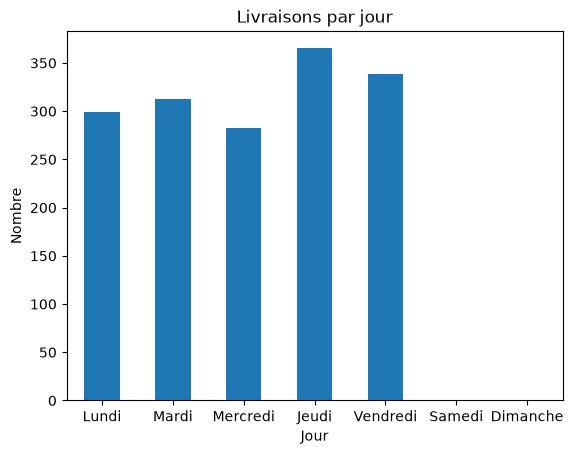

In [44]:
# Distribution des livraisons par jour de la semaine
jours = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]

# Une livraison correspond à un fournisseur, une usine et une date.
livraisons_par_jour = (
    livraisons.assign(date=pd.to_datetime(livraisons["date"]))
    .drop_duplicates(subset=["date", "supplier_id", "plant"])
    .assign(jour_semaine=lambda df: df["date"].dt.day_of_week)
    .groupby("jour_semaine")
    .size()
    .reindex(range(7), fill_value=0)
)

livraisons_par_jour.index = jours
livraisons_par_jour.plot(kind="bar", title="Livraisons par jour", xlabel="Jour", ylabel="Nombre", rot=0)
plt.show()


Les livraisons n'ont lieu qu'en semaine. La charge est assez équilibrée, avec un peu plus de livraisons en fin de semaine : le jeudi est le jour le plus chargé et le mercredi le plus calme. L'écart reste modéré, mais il faudra veiller à ne pas l'accentuer lors de la consolidation, en répartissant les jours de livraison entre les couples d'une même usine (SF-08).

### Fréquence de livraison des couples les plus actifs

La carte de chaleur montre, pour les 10 couples fournisseur × usine qui livrent le plus souvent, le nombre de livraisons par jour de la semaine sur l'horizon du planning.

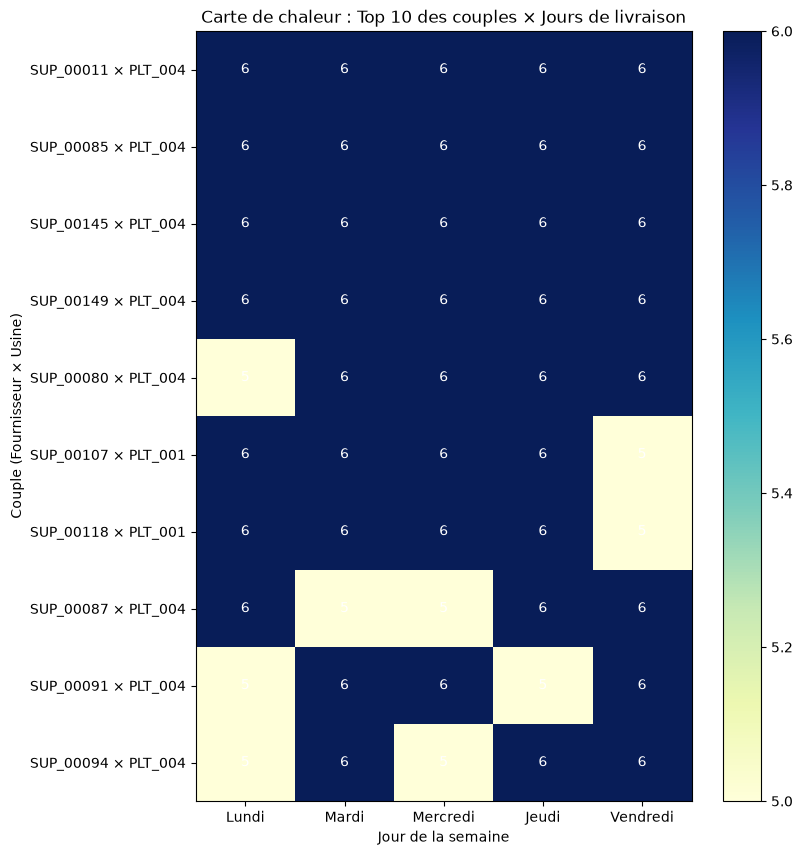

In [45]:
# extraction des livraisons uniques et on définit le couple et le jour
df_livr = livraisons.drop_duplicates(['date', 'supplier_id', 'plant']).copy()
df_livr['couple'] = df_livr['supplier_id'] + " × " + df_livr['plant']
jours_fr = {0: 'Lundi', 1: 'Mardi', 2: 'Mercredi', 3: 'Jeudi', 4: 'Vendredi'}
df_livr['jour'] = pd.to_datetime(df_livr['date']).dt.day_of_week.map(jours_fr)

# nombre de passages pour chaque couple selon le jour
jours = ['Lundi', 'Mardi', 'Mercredi', 'Jeudi', 'Vendredi']
table = pd.crosstab(df_livr['couple'], df_livr['jour'])[jours]

# top 10
top_10 = table.sum(axis=1).nlargest(10).index
heat = table.loc[top_10]

# carte de chaleur avec matplotlib seul
fig, ax = plt.subplots(figsize=(8, 10))
im = ax.imshow(heat.values, cmap="YlGnBu", aspect="auto")
fig.colorbar(im, ax=ax)

ax.set_xticks(range(len(heat.columns)), heat.columns)
ax.set_yticks(range(len(heat.index)), heat.index)

# valeur écrite dans chaque case (en blanc sur les cases foncées)
seuil = heat.values.max() / 2
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        valeur = heat.values[i, j]
        ax.text(j, i, valeur, ha="center", va="center",
                color="white" if valeur > seuil else "black")

ax.set_title("Carte de chaleur : Top 10 des couples × Jours de livraison")
ax.set_xlabel("Jour de la semaine")
ax.set_ylabel("Couple (Fournisseur × Usine)")
plt.show()

Les couples les plus actifs livrent **tous les jours de la semaine** : 5 à 6 livraisons par jour de semaine, soit environ une livraison par jour ouvré sur les 6 semaines du planning. La plupart livrent l'usine **PLT_004**.

Ce sont les meilleurs candidats à la consolidation : passer d'une livraison par jour à 1 ou 2 livraisons par semaine (SF-04, SF-05), en livrant certains besoins en avance (SF-06), réduirait fortement leur nombre de camions sans dépasser la capacité, vu le faible remplissage actuel.

### Remplissage des camions

On analyse le nombre de camions par livraison, puis le poids, le taux de remplissage et le volume de chaque camion.

Nombre de livraisons selon leur nombre de camions :
nb_camions
1    1595
2       4
Name: count, dtype: int64
    supplier_id    plant       date     poids    volume  nb_camions  semaine  \
286   SUP_00037  PLT_002 2026-11-27  25722.70  39.00800           2       48   
418   SUP_00046  PLT_004 2026-11-11  46733.64   6.45408           2       46   
420   SUP_00046  PLT_004 2026-11-25  26535.24   7.37568           2       48   
421   SUP_00046  PLT_004 2026-12-02  32306.82   9.31872           2       49   

     jour  remplissage_poids  
286     4           0.524953  
418     2           0.953748  
420     2           0.541536  
421     2           0.659323  


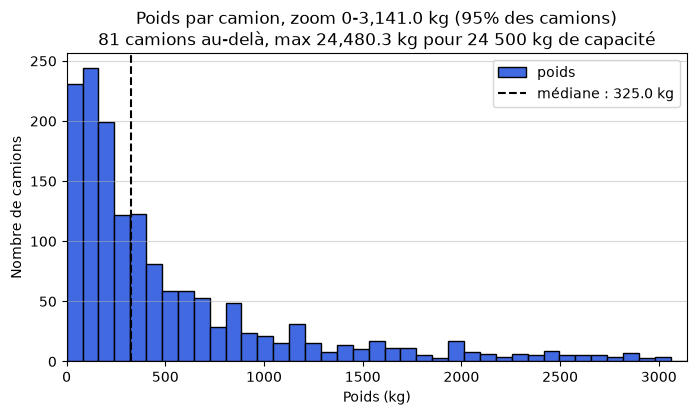

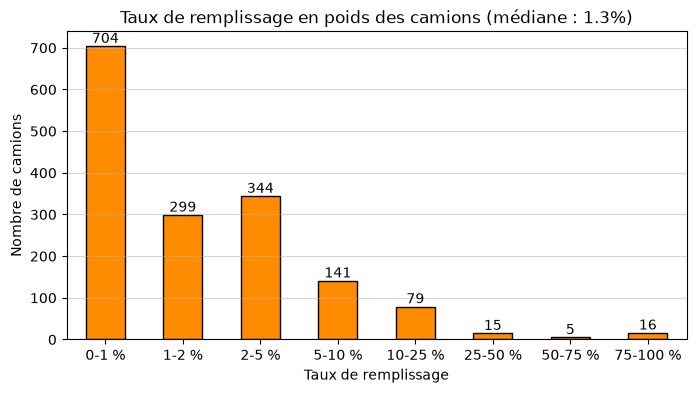

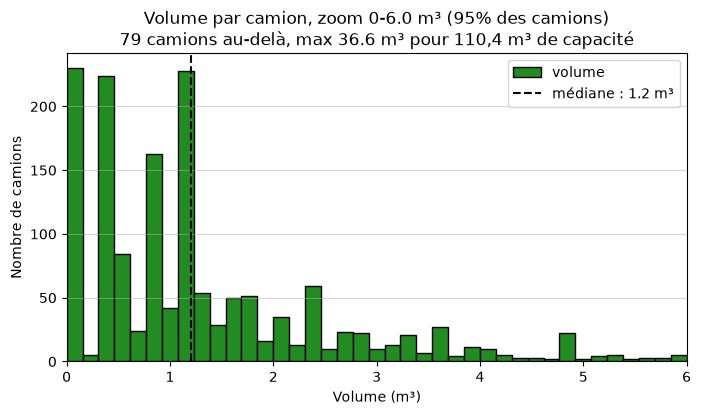

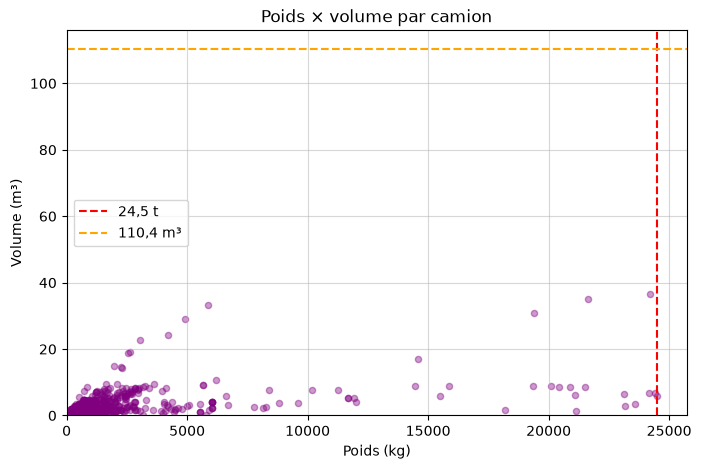

In [46]:
# ---------- Nombre de camions par livraison (tableau, pas de graphique) ----------
print("Nombre de livraisons selon leur nombre de camions :")
print(livraisons["nb_camions"].value_counts().sort_index())
print(livraisons[livraisons["nb_camions"] > 1])

# Zoom automatique : l'axe s'arrête au 95e percentile, les rares valeurs au-delà sont comptées dans le titre
QUANTILE_ZOOM = 0.95

def histogramme_zoom(serie, unite, couleur, titre, ligne_max=None):
    borne = serie.quantile(QUANTILE_ZOOM)
    nb_hors_zoom = (serie > borne).sum()
    serie.plot(kind="hist", bins=np.linspace(0, borne, 40), color=couleur, edgecolor="black", figsize=(8, 4))
    plt.xlim(0, borne)
    plt.axvline(serie.median(), color="black", linestyle="--", label=f"médiane : {serie.median():,.1f} {unite}")
    plt.title(f"{titre}, zoom 0-{borne:,.1f} {unite} ({QUANTILE_ZOOM:.0%} des camions)\n"
              f"{nb_hors_zoom} camions au-delà, max {serie.max():,.1f} {unite} pour {ligne_max} de capacité")
    plt.xlabel(f"{titre.split()[0]} ({unite})")
    plt.ylabel("Nombre de camions")
    plt.legend()
    plt.grid(axis="y", alpha=0.5)
    plt.show()

# ---------- Poids par camion ----------
histogramme_zoom(camions["poids"], "kg", "royalblue", "Poids par camion", ligne_max="24 500 kg")

# ---------- Taux de remplissage en poids par camion ----------
# Par tranches : avec 30 barres de 0 à 100 %, tout serait dans la première
classes = pd.cut(camions["remplissage_poids"] * 100, bins=[0, 1, 2, 5, 10, 25, 50, 75, 100],
                 include_lowest=True).value_counts().sort_index()
classes.index = ["0-1 %", "1-2 %", "2-5 %", "5-10 %", "10-25 %", "25-50 %", "50-75 %", "75-100 %"]
ax = classes.plot(kind="bar", color="darkorange", edgecolor="black", figsize=(8, 4), rot=0)
ax.bar_label(ax.containers[0])
plt.title(f"Taux de remplissage en poids des camions (médiane : {camions['remplissage_poids'].median():.1%})")
plt.xlabel("Taux de remplissage")
plt.ylabel("Nombre de camions")
plt.grid(axis="y", alpha=0.5)
plt.show()

# ---------- Volume par camion ----------
histogramme_zoom(camions["volume"], "m³", "forestgreen", "Volume par camion", ligne_max="110,4 m³")

# ---------- Poids × volume par camion ----------
camions.plot(kind="scatter", x="poids", y="volume", alpha=0.4, color="purple", figsize=(8, 5))
plt.axvline(POIDS_MAX, color="red", linestyle="--", label="24,5 t")
plt.axhline(VOLUME_MAX, color="orange", linestyle="--", label="110,4 m³")
plt.xlim(0, POIDS_MAX * 1.05)
plt.ylim(0, VOLUME_MAX * 1.05)
plt.title("Poids × volume par camion")
plt.xlabel("Poids (kg)")
plt.ylabel("Volume (m³)")
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

- **Nombre de camions** : 1 595 livraisons sur 1 599 tiennent dans un seul camion.
- **Poids** : le poids médian d'un camion est d'environ **325 kg**, pour une capacité de 24 500 kg. La distribution est très étalée (de moins de 1 kg à 24,5 t) : 95 % des camions pèsent moins de 3,2 t, d'où le zoom automatique de l'histogramme.
- **Taux de remplissage** : la médiane est de **1,3 %**. 704 camions sont remplis à moins de 1 %, et environ 84 % des camions le sont à moins de 5 %. Seuls 21 camions dépassent 50 %.
- **Par usine** : le remplissage reste très faible partout. PLT_003 a les camions les plus chargés (médiane d'environ 580 kg), PLT_001 les moins chargés (environ 240 kg).
- **Volume** : le volume médian est d'environ 1,2 m³ et le maximum de 37 m³, très loin de la limite de 110,4 m³. Le nuage poids × volume montre qu'aucun camion n'approche la limite de volume : c'est le **poids** qui limitera la consolidation, pas le volume.

### Conclusion

La baseline confirme que les livraisons actuelles sont **très fragmentées** : 1 603 camions pour 1 599 livraisons, remplis en médiane à 1,3 % de leur capacité. Les couples les plus actifs livrent tous les jours, avec des camions presque vides.

Il y a donc une large marge pour regrouper les besoins de plusieurs jours dans un même camion. Les prochaines étapes sont :
1. **chiffrer la baseline** avec la grille tarifaire (distance × poids, marge et surcharge diesel) pour obtenir le coût actuel par couple ;
2. **construire les profils de livraison** (fréquence et jours fixes) et le contenu de chaque camion consolidé ;
3. **comparer** le coût consolidé à cette baseline pour obtenir l'économie par couple, en € et en % (SF-11).